In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/kushal0418/ess-model-output-51-60-batch/ess_metrics_summary_all_seeds_51_61.csv
/kaggle/input/datasets/kushal0418/ess-model-output-51-60-batch/ess_mixing_observations_all_seeds_51_61.csv
/kaggle/input/datasets/kushal0418/ess-model-output-51-60-batch/ess_train_test_metrics_all_seeds_51_61.csv
/kaggle/input/datasets/kushal0418/ess-model-output-51-60-batch/ordinal_ess_train_test_metrics.csv
/kaggle/input/datasets/kushal0418/ess-model-output-51-60-batch/ordinal_ess_train_test_metrics_summary.csv
/kaggle/input/datasets/kushal0418/ess-model-output-51-60-batch/.virtual_documents/__notebook_source__.ipynb
/kaggle/input/datasets/kushal0418/ess-model-output-42-50-batch/ess_metrics_summary_all_seeds_40_41.csv
/kaggle/input/datasets/kushal0418/ess-model-output-42-50-batch/ess_metrics_summary_all_seeds_42_50.csv
/kaggle/input/datasets/kushal0418/ess-model-output-42-50-batch/ess_mixing_observations_all_seeds_40_41.csv
/kaggle/input/datasets/kushal0418/ess-model-output-42-50-ba

# ESS Output Analysis

In [3]:
batch_list = ['40_41','42_50','51_61']
folder_name_40_50 =  '/kaggle/input/datasets/kushal0418/ess-model-output-42-50-batch'
folder_name_51_60 = '/kaggle/input/datasets/kushal0418/ess-model-output-51-60-batch'
data_summary = pd.DataFrame()
data_train_test_metrics = pd.DataFrame()
data_mixing = pd.DataFrame()
for batch in batch_list:
    if (batch == '40_41') | (batch == '42_50'):
        # print('going in 40 to 50')
        file_name_summary = '{folder_name}/ess_metrics_summary_all_seeds_{batch_name}.csv'.format(folder_name = folder_name_40_50,batch_name = batch)
        file_name_train_test_metrics = '{folder_name}/ess_train_test_metrics_all_seeds_{batch_name}.csv'.format(folder_name = folder_name_40_50,batch_name = batch)
        file_name_mixing = '{folder_name}/ess_mixing_observations_all_seeds_{batch_name}.csv'.format(folder_name = folder_name_40_50,batch_name = batch)
    else:
        # print('going in 51-61')
        file_name_summary = '{folder_name}/ess_metrics_summary_all_seeds_{batch_name}.csv'.format(folder_name = folder_name_51_60,batch_name = batch)
        file_name_train_test_metrics = '{folder_name}/ess_train_test_metrics_all_seeds_{batch_name}.csv'.format(folder_name = folder_name_51_60,batch_name = batch)
        file_name_mixing = '{folder_name}/ess_mixing_observations_all_seeds_{batch_name}.csv'.format(folder_name = folder_name_51_60,batch_name = batch)
    df_summ = pd.read_csv(file_name_summary)
    df_train_test_metrics = pd.read_csv(file_name_train_test_metrics)
    df_mixing = pd.read_csv(file_name_mixing)
    data_summary = pd.concat([data_summary,df_summ],axis = 0)
    data_train_test_metrics = pd.concat([data_train_test_metrics,df_train_test_metrics],axis = 0)
    data_mixing = pd.concat([data_mixing,df_mixing],axis = 0)

In [4]:
data_train_test_metrics

,random_seed,data,n_samples,accuracy,precision,recall,f1_score
0,40,train,2400,0.599583,0.537611,0.544543,0.537975
1,40,test,600,0.571667,0.528931,0.531311,0.529937
2,41,train,2400,0.588333,0.529737,0.536049,0.530991
3,41,test,600,0.613333,0.553867,0.557257,0.552160
0,43,train,2400,0.588750,0.528842,0.535328,0.530322
1,43,test,600,0.605000,0.552607,0.553793,0.548827
2,44,train,2400,0.591250,0.532066,0.538150,0.532842
3,44,test,600,0.598333,0.542256,0.547858,0.543454
4,45,train,2400,0.590000,0.532332,0.537740,0.533368
5,45,test,600,0.605000,0.544178,0.550197,0.543250


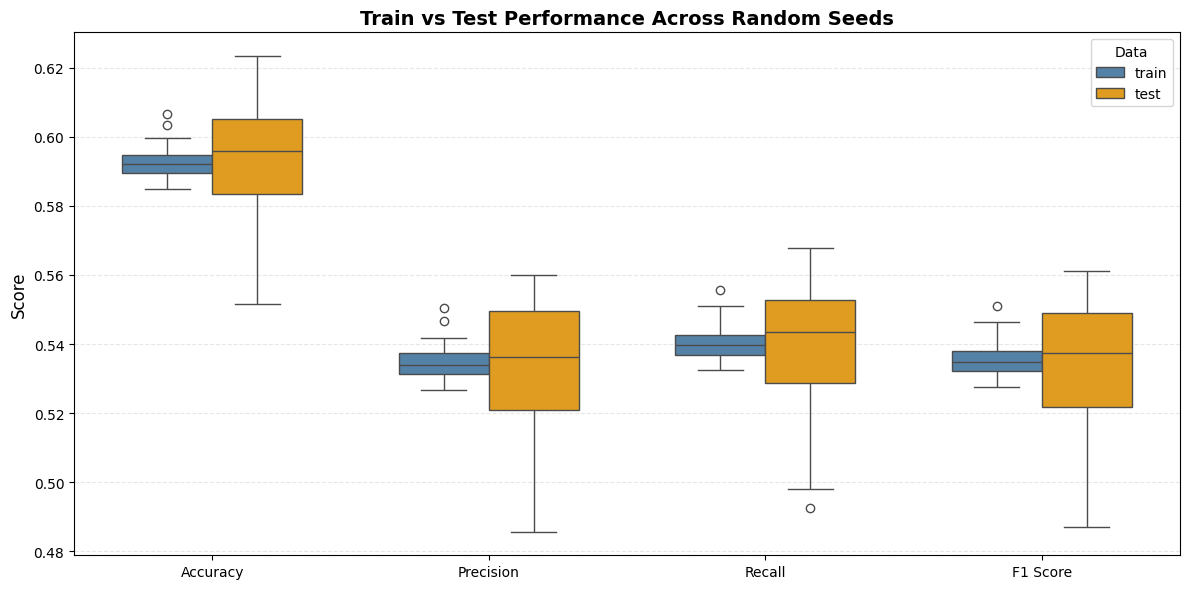

In [5]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Metrics to plot
metrics = ['accuracy', 'precision', 'recall', 'f1_score']

# Convert dataframe from wide to long format
data_long = data_train_test_metrics.melt(
    id_vars=['random_seed', 'data', 'n_samples'],
    value_vars=metrics,
    var_name='Metric',
    value_name='Score'
)

# Make metric names cleaner
data_long['Metric'] = data_long['Metric'].replace({
    'accuracy': 'Accuracy',
    'precision': 'Precision',
    'recall': 'Recall',
    'f1_score': 'F1 Score'
})

# Create figure
plt.figure(figsize=(12, 6))

# Side-by-side Train and Test boxplots
sns.boxplot(
    data=data_long,
    x='Metric',
    y='Score',
    hue='data',
    hue_order=['train', 'test'],
    palette={
        'train': 'steelblue',
        'test': 'orange'
    },
    width=0.65
)

plt.title(
    'Train vs Test Performance Across Random Seeds',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('')
plt.ylabel('Score', fontsize=12)

plt.legend(
    title='Data',
    loc='best'
)

plt.grid(
    axis='y',
    linestyle='--',
    alpha=0.3
)

plt.tight_layout()
plt.show()

# ML Models Results

In [8]:
df_ml_all = pd.read_csv('/kaggle/input/datasets/kushal0418/ml-experiment-output-ess/ess_expt_model_output_ml.csv')

In [9]:
df_ml_all.columns

Index(['random_seed', 'model', 'data', 'n_samples', 'accuracy', 'precision',
       'recall', 'f1_score'],
      dtype='object')

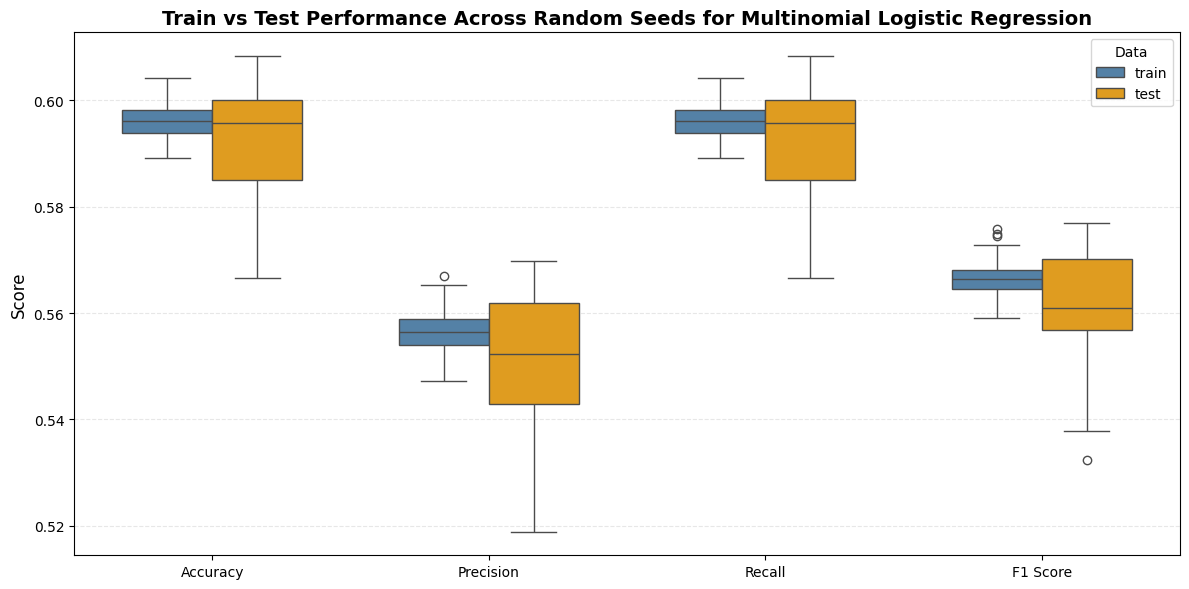

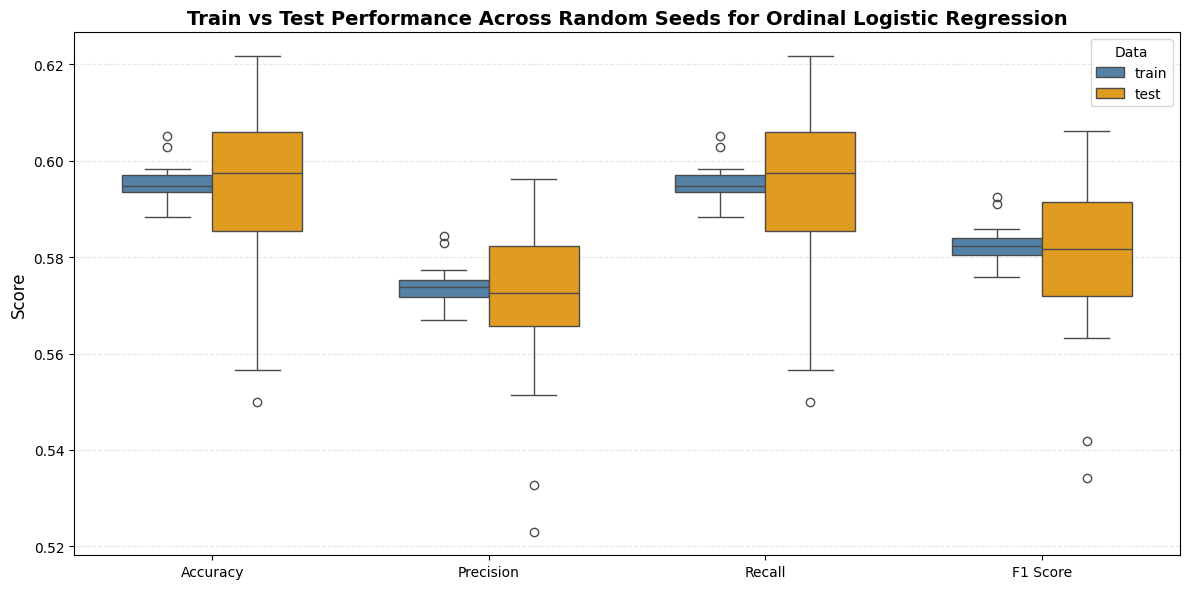

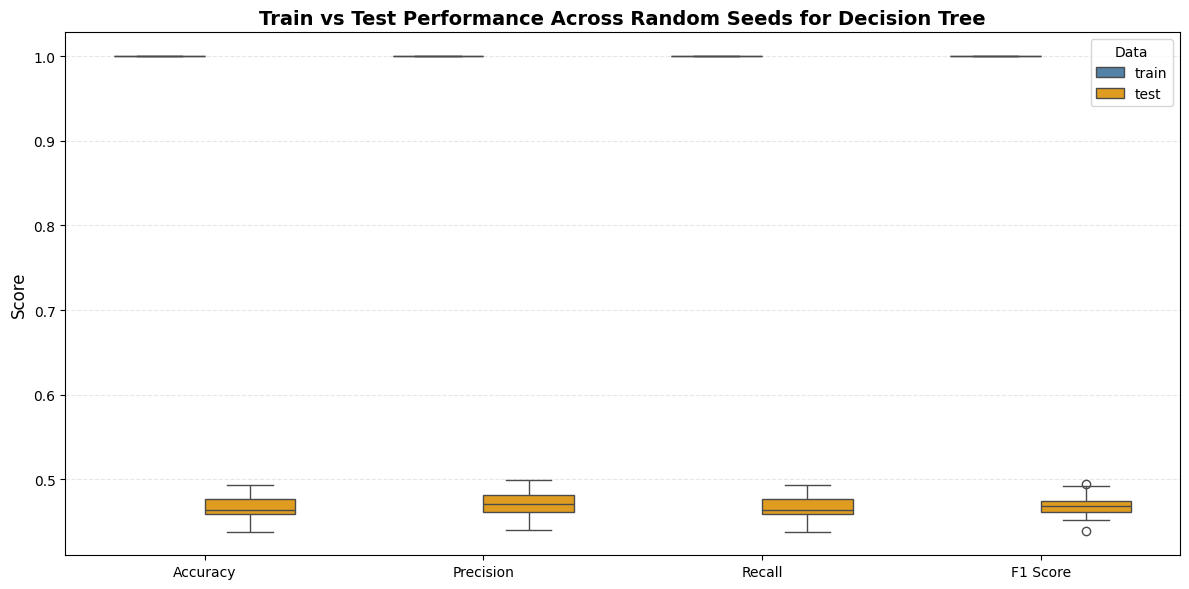

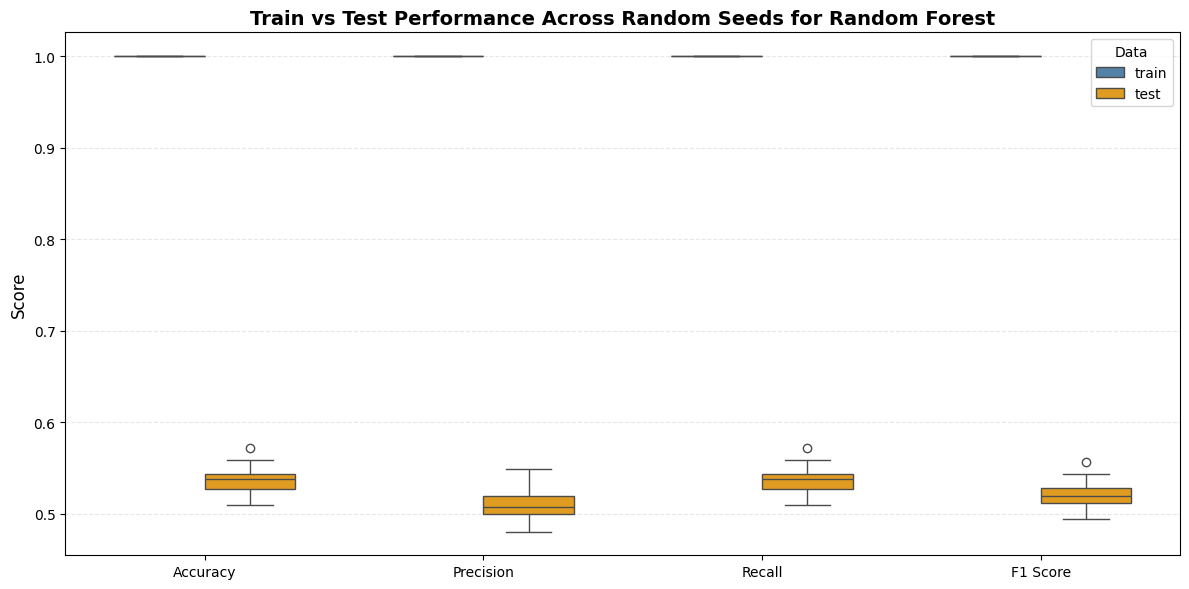

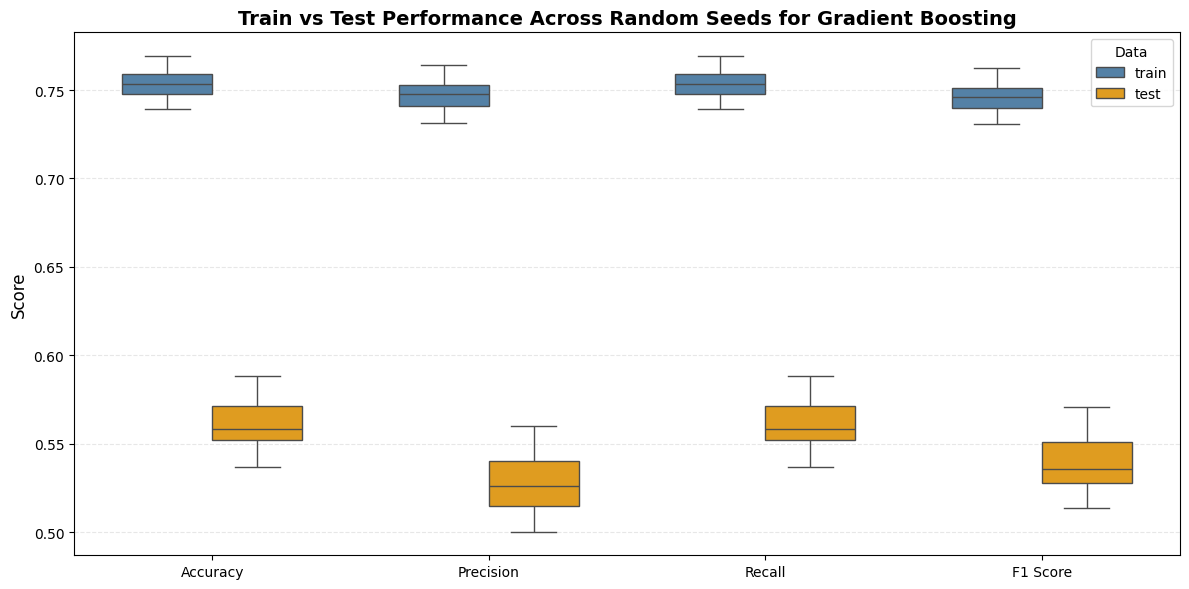

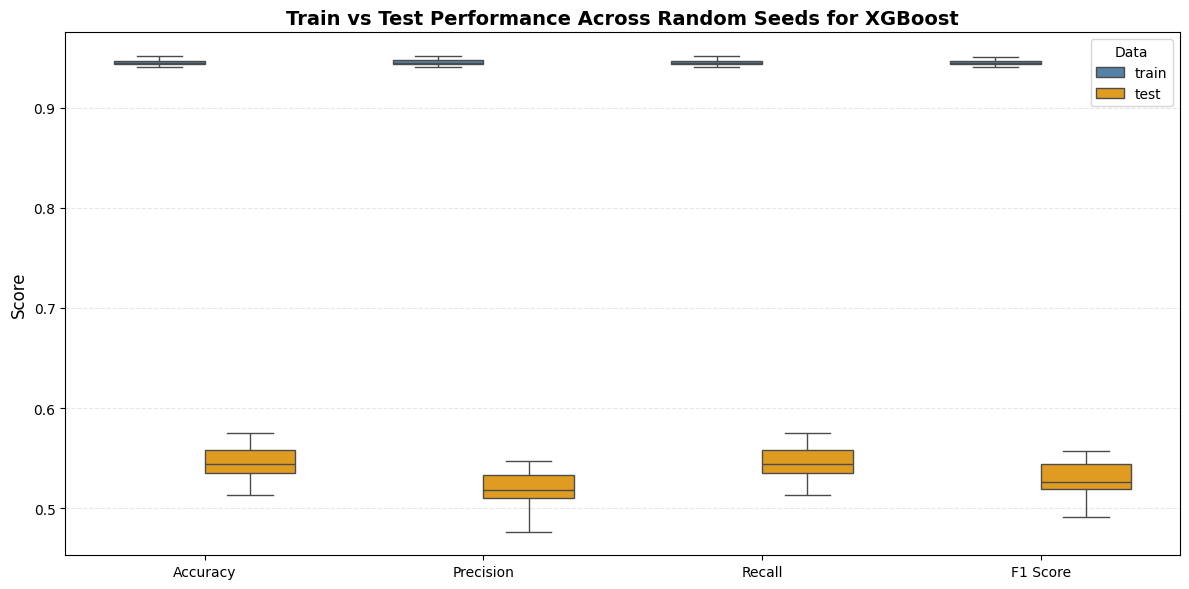

In [10]:
ml_models_unique = list(df_ml_all['model'].value_counts().index)
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

for model in ml_models_unique:
    df_ml = df_ml_all[df_ml_all['model'] == model]
    # Metrics to plot
    metrics = ['accuracy', 'precision', 'recall', 'f1_score']
    
    # Convert dataframe from wide to long format
    data_long = df_ml.melt(
        id_vars=['random_seed', 'data', 'n_samples'],
        value_vars=metrics,
        var_name='Metric',
        value_name='Score'
    )
    
    # Make metric names cleaner
    data_long['Metric'] = data_long['Metric'].replace({
        'accuracy': 'Accuracy',
        'precision': 'Precision',
        'recall': 'Recall',
        'f1_score': 'F1 Score'
    })
    
    # Create figure
    plt.figure(figsize=(12, 6))
    
    # Side-by-side Train and Test boxplots
    sns.boxplot(
        data=data_long,
        x='Metric',
        y='Score',
        hue='data',
        hue_order=['train', 'test'],
        palette={
            'train': 'steelblue',
            'test': 'orange'
        },
        width=0.65
    )
    
    plt.title(
        'Train vs Test Performance Across Random Seeds for {model_name}'.format(model_name = model),
        fontsize=14,
        fontweight='bold'
    )
    
    plt.xlabel('')
    plt.ylabel('Score', fontsize=12)
    
    plt.legend(
        title='Data',
        loc='best'
    )
    
    plt.grid(
        axis='y',
        linestyle='--',
        alpha=0.3
    )
    
    plt.tight_layout()
    plt.show()

# ESS Mixing Plot

In [12]:
data_mixing.columns

Index(['random_seed', 'sample', 'chain', 'z_1', 'z_2', 'z_3', 'z_4', 'z_5',
       'z_6', 'z_7', 'z_8', 'z_9', 'theta_1', 'theta_2', 'theta_3', 'theta_4',
       'theta_5', 'theta_6', 'theta_7', 'theta_8', 'theta_9', 'beta_1',
       'beta_2', 'beta_3', 'beta_4', 'beta_5', 'beta_6', 'gamma_1', 'gamma_2',
       'gamma_3', 'cutpoint_1', 'cutpoint_2', 'cutpoint_3'],
      dtype='object')

In [13]:
data_mixing.rename({'beta_1':'beta_x1',
                    'beta_2':'beta_x2',
                    'beta_3':'beta_x3',
                    'beta_4':'beta_cat1_B',
                   'beta_5':'beta_cat1_C',
                   'beta_6':'beta_cat2_Yes'},axis = 1,inplace = True)

In [16]:
data_mixing

,random_seed,sample,chain,z_1,z_2,z_3,z_4,z_5,z_6,z_7,...,beta_x3,beta_cat1_B,beta_cat1_C,beta_cat2_Yes,gamma_1,gamma_2,gamma_3,cutpoint_1,cutpoint_2,cutpoint_3
0,40,1,1,0.725727,-0.618946,0.549177,0.461296,-0.511748,0.479595,-1.208806,...,1.372943,1.153239,-1.279371,1.198987,-1.813209,1.664950,1.568167,-1.813209,0.025022,1.782508
1,40,2,1,0.726566,-0.621590,0.550528,0.461448,-0.508978,0.476224,-1.207759,...,1.376321,1.153620,-1.272445,1.190560,-1.811639,1.666046,1.569734,-1.811639,0.027514,1.786297
2,40,3,1,0.729069,-0.618575,0.548318,0.459814,-0.508925,0.477455,-1.208636,...,1.370796,1.149534,-1.272313,1.193636,-1.812955,1.667361,1.571367,-1.812955,0.027304,1.787439
3,40,4,1,0.713823,-0.596596,0.533158,0.437117,-0.475138,0.472218,-1.186251,...,1.332896,1.092792,-1.187845,1.180545,-1.779376,1.638677,1.566596,-1.779376,0.036809,1.792995
4,40,5,1,0.712295,-0.596540,0.533043,0.435291,-0.476157,0.473087,-1.187480,...,1.332607,1.088227,-1.190393,1.182718,-1.781221,1.640202,1.567952,-1.781221,0.036240,1.793549
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119995,60,2996,4,0.739925,-0.622359,0.554601,0.522284,-0.542857,0.425543,-1.080921,...,1.386502,1.305711,-1.357143,1.063857,-1.621382,1.566939,1.436443,-1.621382,0.135089,1.784845
119996,60,2997,4,0.730292,-0.599235,0.531925,0.528871,-0.508877,0.427600,-1.085887,...,1.329812,1.322179,-1.272192,1.069000,-1.628831,1.579298,1.437948,-1.628831,0.137875,1.788847
119997,60,2998,4,0.727897,-0.598148,0.530899,0.526781,-0.510156,0.426440,-1.085753,...,1.327246,1.316954,-1.275391,1.066099,-1.628629,1.580652,1.434750,-1.628629,0.139200,1.787588
119998,60,2999,4,0.728017,-0.593806,0.535110,0.537555,-0.481579,0.448446,-1.107283,...,1.337776,1.343886,-1.203947,1.121114,-1.660925,1.608275,1.458905,-1.660925,0.129865,1.797807


# Interactive line Chart

In [17]:
import json
from pathlib import Path

import pandas as pd
import plotly.graph_objects as go


def create_posterior_mixing_dashboard(
    data,
    output_html="posterior_mixing_dashboard.html",
    random_seed_col="random_seed",
    chain_col="chain",
    sample_col="sample"
):
    """
    Create an interactive Plotly HTML dashboard for posterior mixing / MCMC traces.

    Parameters
    ----------
    data : pandas.DataFrame or str or pathlib.Path
        Either:
        1. A pandas DataFrame, or
        2. Path to a flat file such as .csv, .txt, .tsv, .parquet, or .feather

    output_html : str
        Name/path of the output HTML file.

    random_seed_col : str
        Column containing the random seed.

    chain_col : str
        Column containing the MCMC chain number.

    sample_col : str
        Column containing the posterior sample / iteration number.

    Returns
    -------
    str
        Path of the generated interactive HTML file.
    """

    # ============================================================
    # 1. LOAD THE DATA
    # ============================================================

    if isinstance(data, pd.DataFrame):
        df = data.copy()

    elif isinstance(data, (str, Path)):

        data = Path(data)

        suffix = data.suffix.lower()

        if suffix == ".csv":
            df = pd.read_csv(data)

        elif suffix in [".txt", ".tsv"]:
            df = pd.read_csv(data, sep=None, engine="python")

        elif suffix == ".parquet":
            df = pd.read_parquet(data)

        elif suffix == ".feather":
            df = pd.read_feather(data)

        else:
            raise ValueError(
                f"Unsupported input file type: {suffix}\n"
                "Supported formats: .csv, .txt, .tsv, .parquet, .feather"
            )

    else:
        raise TypeError(
            "'data' must be either a pandas DataFrame or a file path."
        )

    print(f"Data loaded: {df.shape,} rows x {df.shape[1]} columns")


    # ============================================================
    # 2. CHECK REQUIRED COLUMNS
    # ============================================================

    required_cols = [
        random_seed_col,
        chain_col,
        sample_col
    ]

    missing_cols = [
        col for col in required_cols
        if col not in df.columns
    ]

    if missing_cols:
        raise ValueError(
            f"Required columns missing from the data: {missing_cols}"
        )


    # ============================================================
    # 3. IDENTIFY POSTERIOR ATTRIBUTES
    # ============================================================

    excluded_cols = {
        random_seed_col,
        chain_col,
        sample_col
    }

    attributes = [
        col
        for col in df.columns
        if col not in excluded_cols
    ]

    if len(attributes) == 0:
        raise ValueError(
            "No posterior attribute columns were found."
        )

    print(f"Posterior attributes detected: {len(attributes)}")


    # ============================================================
    # 4. SORT DATA
    # ============================================================

    df = (
        df.sort_values(
            by=[
                random_seed_col,
                chain_col,
                sample_col
            ]
        )
        .reset_index(drop=True)
    )


    # ============================================================
    # 5. GET AVAILABLE SEEDS AND CHAINS
    # ============================================================

    random_seeds = (
        df[random_seed_col]
        .dropna()
        .unique()
        .tolist()
    )

    try:
        random_seeds = sorted(random_seeds)
    except TypeError:
        random_seeds = list(random_seeds)

    chains_by_seed = {}

    for seed in random_seeds:

        chains = (
            df.loc[
                df[random_seed_col] == seed,
                chain_col
            ]
            .dropna()
            .unique()
            .tolist()
        )

        try:
            chains = sorted(chains)
        except TypeError:
            pass

        chains_by_seed[str(seed)] = chains


    # ============================================================
    # 6. DEFAULT SELECTION
    # ============================================================

    default_seed = random_seeds[0]

    default_chain = chains_by_seed[
        str(default_seed)
    ][0]

    default_attribute = attributes[0]


    # ============================================================
    # 7. CREATE INITIAL TRACE
    # ============================================================

    temp = df[
        (df[random_seed_col] == default_seed)
        &
        (df[chain_col] == default_chain)
    ]

    fig = go.Figure()

    fig.add_trace(
        go.Scatter(
            x=temp[sample_col],
            y=temp[default_attribute],
            mode="lines",
            line=dict(
                width=1.5,
                color="#0078D4"
            ),
            hovertemplate=(
                "Sample: %{x}<br>"
                + default_attribute
                + ": %{y:.6f}"
                + "<extra></extra>"
            )
        )
    )


    # ============================================================
    # 8. FIGURE LAYOUT
    # ============================================================

    fig.update_layout(

        title=dict(
            text=(
                f"Posterior Mixing Trace"
                f"<br>"
                f"<sup>"
                f"Random Seed = {default_seed} | "
                f"Chain = {default_chain} | "
                f"Attribute = {default_attribute}"
                f"</sup>"
            ),
            x=0.5
        ),

        xaxis=dict(
            title="Posterior Sample / Iteration",
            showgrid=True
        ),

        yaxis=dict(
            title=default_attribute,
            showgrid=True
        ),

        template="plotly_white",

        hovermode="x unified",

        height=650,

        margin=dict(
            l=80,
            r=40,
            t=100,
            b=80
        )
    )


    # ============================================================
    # 9. CONVERT DATA FOR JAVASCRIPT
    # ============================================================

    # Only store columns required by the dashboard
    dashboard_columns = (
        [random_seed_col, chain_col, sample_col]
        + attributes
    )

    dashboard_df = df[dashboard_columns].copy()

    # Replace missing values with None so JSON produces null.
    dashboard_df = dashboard_df.astype(object).where(
        pd.notnull(dashboard_df),
        None
    )

    records = dashboard_df.to_dict(orient="records")

    data_json = json.dumps(
        records,
        separators=(",", ":")
    )

    random_seeds_json = json.dumps(random_seeds)

    chains_json = json.dumps(chains_by_seed)

    attributes_json = json.dumps(attributes)

    config_json = json.dumps(
        {
            "seedColumn": random_seed_col,
            "chainColumn": chain_col,
            "sampleColumn": sample_col
        }
    )


    # ============================================================
    # 10. GENERATE THE PLOTLY HTML
    # ============================================================

    plot_html = fig.to_html(
        full_html=False,
        include_plotlyjs=True,
        div_id="posterior_trace_plot",
        config={
            "responsive": True,
            "displaylogo": False
        }
    )


    # ============================================================
    # 11. CREATE CUSTOM HTML DROPDOWNS
    # ============================================================

    custom_html = f"""
<!DOCTYPE html>
<html>

<head>

<meta charset="utf-8">

<title>Posterior Mixing Dashboard</title>

<style>

body {{
    font-family:
        -apple-system,
        BlinkMacSystemFont,
        "Segoe UI",
        Arial,
        sans-serif;

    background-color: #f7f9fc;

    margin: 0;
    padding: 25px;
}}

.dashboard-container {{
    max-width: 1500px;
    margin: auto;
}}

.dashboard-title {{
    text-align: center;
    color: #222;
    margin-bottom: 10px;
}}

.dashboard-subtitle {{
    text-align: center;
    color: #666;
    margin-bottom: 25px;
}}

.control-panel {{

    background: white;

    border-radius: 10px;

    padding: 20px;

    margin-bottom: 20px;

    box-shadow:
        0 2px 8px
        rgba(0, 0, 0, 0.08);

    display: flex;

    flex-wrap: wrap;

    gap: 25px;

    align-items: end;
}}

.control-group {{

    display: flex;

    flex-direction: column;

    min-width: 200px;
}}

.control-group label {{

    font-weight: 600;

    margin-bottom: 7px;

    color: #333;
}}

.control-group select {{

    padding: 9px 12px;

    border: 1px solid #cccccc;

    border-radius: 5px;

    background-color: white;

    font-size: 15px;
}}

.plot-container {{

    background: white;

    border-radius: 10px;

    padding: 10px;

    box-shadow:
        0 2px 8px
        rgba(0, 0, 0, 0.08);
}}

</style>

</head>


<body>

<div class="dashboard-container">

    <h1 class="dashboard-title">
        Posterior Mixing Dashboard
    </h1>

    <div class="dashboard-subtitle">
        Interactive MCMC trace inspection by random seed,
        chain and posterior attribute
    </div>


    <div class="control-panel">


        <div class="control-group">

            <label for="seedSelect">
                Random Seed
            </label>

            <select id="seedSelect"></select>

        </div>


        <div class="control-group">

            <label for="chainSelect">
                Chain
            </label>

            <select id="chainSelect"></select>

        </div>


        <div class="control-group">

            <label for="attributeSelect">
                Attribute
            </label>

            <select id="attributeSelect"></select>

        </div>


    </div>


    <div class="plot-container">

        {plot_html}

    </div>


</div>


<script>

const posteriorData = {data_json};

const availableSeeds = {random_seeds_json};

const chainsBySeed = {chains_json};

const availableAttributes = {attributes_json};

const config = {config_json};


const seedSelect =
    document.getElementById("seedSelect");

const chainSelect =
    document.getElementById("chainSelect");

const attributeSelect =
    document.getElementById("attributeSelect");


/*
============================================================
Populate random seed dropdown
============================================================
*/

availableSeeds.forEach(seed => {{

    const option =
        document.createElement("option");

    option.value = seed;

    option.text = seed;

    seedSelect.appendChild(option);

}});


/*
============================================================
Populate attribute dropdown
============================================================
*/

availableAttributes.forEach(attribute => {{

    const option =
        document.createElement("option");

    option.value = attribute;

    option.text = attribute;

    attributeSelect.appendChild(option);

}});


/*
============================================================
Update chain dropdown according to selected seed
============================================================
*/

function updateChainDropdown() {{

    const selectedSeed =
        seedSelect.value;

    const chains =
        chainsBySeed[String(selectedSeed)];

    chainSelect.innerHTML = "";

    chains.forEach(chain => {{

        const option =
            document.createElement("option");

        option.value = chain;

        option.text = chain;

        chainSelect.appendChild(option);

    }});

}}


/*
============================================================
Update the posterior mixing graph
============================================================
*/

function updatePlot() {{

    const selectedSeed =
        seedSelect.value;

    const selectedChain =
        chainSelect.value;

    const selectedAttribute =
        attributeSelect.value;


    /*
    --------------------------------------------------------
    Filter data
    --------------------------------------------------------
    */

    const filteredData =
        posteriorData.filter(row =>

            String(row[config.seedColumn]) ===
            String(selectedSeed)

            &&

            String(row[config.chainColumn]) ===
            String(selectedChain)

        );


    /*
    --------------------------------------------------------
    Sort by sample
    --------------------------------------------------------
    */

    filteredData.sort(
        (a, b) =>
            Number(a[config.sampleColumn]) -
            Number(b[config.sampleColumn])
    );


    /*
    --------------------------------------------------------
    Extract X/Y
    --------------------------------------------------------
    */

    const xValues =
        filteredData.map(
            row => row[config.sampleColumn]
        );

    const yValues =
        filteredData.map(
            row => row[selectedAttribute]
        );


    /*
    --------------------------------------------------------
    Update Plotly trace
    --------------------------------------------------------
    */

    Plotly.react(

        "posterior_trace_plot",

        [
            {{
                x: xValues,

                y: yValues,

                type: "scatter",

                mode: "lines",

                line: {{
                    width: 1.5,
                    color: "#0078D4"
                }},

                hovertemplate:
                    "Sample: %{{x}}<br>" +
                    selectedAttribute +
                    ": %{{y:.6f}}" +
                    "<extra></extra>"
            }}
        ],

        {{
            title: {{

                text:
                    "Posterior Mixing Trace" +
                    "<br>" +
                    "<sup>" +
                    "Random Seed = " +
                    selectedSeed +
                    " | Chain = " +
                    selectedChain +
                    " | Attribute = " +
                    selectedAttribute +
                    "</sup>",

                x: 0.5
            }},

            xaxis: {{

                title:
                    "Posterior Sample / Iteration",

                showgrid: true
            }},

            yaxis: {{

                title:
                    selectedAttribute,

                showgrid: true
            }},

            template:
                "plotly_white",

            hovermode:
                "x unified",

            height:
                650,

            margin: {{

                l: 80,

                r: 40,

                t: 100,

                b: 80
            }}
        }},

        {{
            responsive: true,

            displaylogo: false
        }}

    );

}}


/*
============================================================
Event listeners
============================================================
*/

seedSelect.addEventListener(
    "change",
    function() {{

        updateChainDropdown();

        updatePlot();

    }}
);


chainSelect.addEventListener(
    "change",
    updatePlot
);


attributeSelect.addEventListener(
    "change",
    updatePlot
);


/*
============================================================
Initialize
============================================================
*/

updateChainDropdown();

updatePlot();

</script>


</body>

</html>
"""


    # ============================================================
    # 12. SAVE THE HTML
    # ============================================================

    output_html = Path(output_html)

    with open(
        output_html,
        "w",
        encoding="utf-8"
    ) as f:

        f.write(custom_html)


    print(
        f"Interactive posterior mixing dashboard saved to:\n"
        f"{output_html.resolve()}"
    )

    print(
        f"\nRandom seeds: {len(random_seeds)}"
        f"\nAttributes: {len(attributes)}"
        f"\nRows: {len(df):,}"
    )

    return str(output_html.resolve())

In [20]:
data_mixing.columns

Index(['random_seed', 'sample', 'chain', 'z_1', 'z_2', 'z_3', 'z_4', 'z_5',
       'z_6', 'z_7', 'z_8', 'z_9', 'theta_1', 'theta_2', 'theta_3', 'theta_4',
       'theta_5', 'theta_6', 'theta_7', 'theta_8', 'theta_9', 'beta_x1',
       'beta_x2', 'beta_x3', 'beta_cat1_B', 'beta_cat1_C', 'beta_cat2_Yes',
       'gamma_1', 'gamma_2', 'gamma_3', 'cutpoint_1', 'cutpoint_2',
       'cutpoint_3'],
      dtype='object')

In [21]:
data_mixing_plot = data_mixing[['random_seed', 'sample', 'chain','beta_x1',
       'beta_x2', 'beta_x3', 'beta_cat1_B', 'beta_cat1_C', 'beta_cat2_Yes','cutpoint_1', 'cutpoint_2',
       'cutpoint_3']]

In [22]:
create_posterior_mixing_dashboard(
    data_mixing_plot,
    output_html="posterior_mixing_dashboard.html",
    random_seed_col="random_seed",
    chain_col="chain",
    sample_col="sample"
)

Data loaded: ((240000, 12),) rows x 12 columns
Posterior attributes detected: 9
Interactive posterior mixing dashboard saved to:
/kaggle/working/posterior_mixing_dashboard.html

Random seeds: 20
Attributes: 9
Rows: 240,000


'/kaggle/working/posterior_mixing_dashboard.html'